# Flow matching vs DDPM, and what LoRA costs when a diffusion model learns new concepts

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

Everything below is plain PyTorch: a small class-conditional U-Net with self-attention, two training objectives (DDPM ε-prediction with a cosine schedule, and rectified flow / flow matching with logit-normal time sampling as in SD3), classifier-free guidance, DDIM and Euler samplers, LoRA for both `Linear` and `Conv2d` layers, and the evaluation code.

**Questions**

1. At the same number of network evaluations (NFE), does flow matching sampled with Euler beat DDPM sampled with DDIM? How does the guidance scale trade sample quality against class adherence?
2. A trained model must learn two new classes from 200 images each. How do embedding-only tuning (textual-inversion style), LoRA (rank 4 and 16) and full fine-tuning compare on the new classes, and how much do they damage the eight classes the model already knew?
3. Which inference optimizations pay off for this model (mixed precision, `channels_last`, `torch.compile`, batch size, merged vs unmerged LoRA), and do they change the samples?

**Data.** Fashion-MNIST (28×28, 10 classes). Classes 0–7 are used for pretraining; *Bag* (8) and *Ankle boot* (9) are held out as the new concepts.

**Run.** Colab → *Runtime → Change runtime type → T4 GPU* → *Run all* (about 40 minutes). Outputs go to `MyDrive/genai-diffusion-lab/`. If the session disconnects, *Run all* again: finished steps are loaded from Drive and skipped. On a CPU-only runtime the notebook switches to a reduced FAST budget.

In [1]:
import os, sys, json, math, time, gzip, copy, random, warnings, urllib.request, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg

IN_COLAB = "google.colab" in sys.modules
GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if GPU else "cpu")
SMOKE = os.environ.get("SMOKE") == "1"   # tiny end-to-end check of the code path, not for results
MODE = "SMOKE" if SMOKE else ("FULL" if GPU else "FAST")

if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", timeout_ms=60000)
        OUT = Path("/content/drive/MyDrive/genai-diffusion-lab")
    except Exception as e:  # Drive is optional; results then only live in the session
        print("Drive not mounted, writing to /content/outputs:", e)
        OUT = Path("/content/outputs")
else:
    OUT = Path("outputs")
CKPT, RES, FIG, DATA = OUT / "checkpoints", OUT / "results", OUT / "figures", OUT / "data"
for d in (CKPT, RES, FIG, DATA):
    d.mkdir(parents=True, exist_ok=True)

BUDGET = {
    "FULL":  dict(pretrain_steps=10000, batch=128, adapt_steps=1200, k_shot=200, seeds=[0, 1, 2], n_eval=4000, cls_epochs=4,
                  nfe=[4, 8, 16, 32, 64], ref_steps=32),
    "FAST":  dict(pretrain_steps=2500, batch=128, adapt_steps=300, k_shot=200, seeds=[0, 1], n_eval=800, cls_epochs=2,
                  nfe=[4, 8, 16, 32], ref_steps=16),
    "SMOKE": dict(pretrain_steps=20, batch=32, adapt_steps=6, k_shot=20, seeds=[0], n_eval=80, cls_epochs=1,
                  nfe=[2, 4], ref_steps=4),
}[MODE]

# fp16 on the GPU; bf16 only on CPUs that support it natively (AMX / AVX512-BF16), otherwise plain fp32
if GPU:
    AMP_DTYPE, USE_AMP = torch.float16, True
else:
    AMP_DTYPE = torch.bfloat16
    USE_AMP = bool(getattr(torch.ops.mkldnn, "_is_mkldnn_bf16_supported", lambda: False)())
torch.backends.cudnn.benchmark = True


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU:
        torch.cuda.manual_seed_all(s)


def autocast(enabled=None):
    on = USE_AMP if enabled is None else enabled
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE) if on else contextlib.nullcontext()


def sync():
    if GPU:
        torch.cuda.synchronize()


def save_json(obj, path):
    tmp = Path(str(path) + ".tmp"); tmp.write_text(json.dumps(obj, indent=2)); tmp.replace(path)


def load_json(path, default=None):
    return json.loads(Path(path).read_text()) if Path(path).exists() else default


env = dict(mode=MODE, torch=torch.__version__, python=sys.version.split()[0], device=str(DEVICE),
           gpu=torch.cuda.get_device_name(0) if GPU else None, amp=str(AMP_DTYPE) if USE_AMP else "off")
save_json(env, RES / "environment.json")
print(env)
print(BUDGET)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'mode': 'FULL', 'torch': '2.14.1+cu130', 'python': '3.13.16', 'device': 'cuda', 'gpu': 'Tesla T4', 'amp': 'torch.float16'}
{'pretrain_steps': 10000, 'batch': 128, 'adapt_steps': 1200, 'k_shot': 200, 'seeds': [0, 1, 2], 'n_eval': 4000, 'cls_epochs': 4, 'nfe': [4, 8, 16, 32, 64], 'ref_steps': 32}


## Data

train (60000, 1, 28, 28), test (10000, 1, 28, 28); pretraining uses 48000 images of classes 0-7


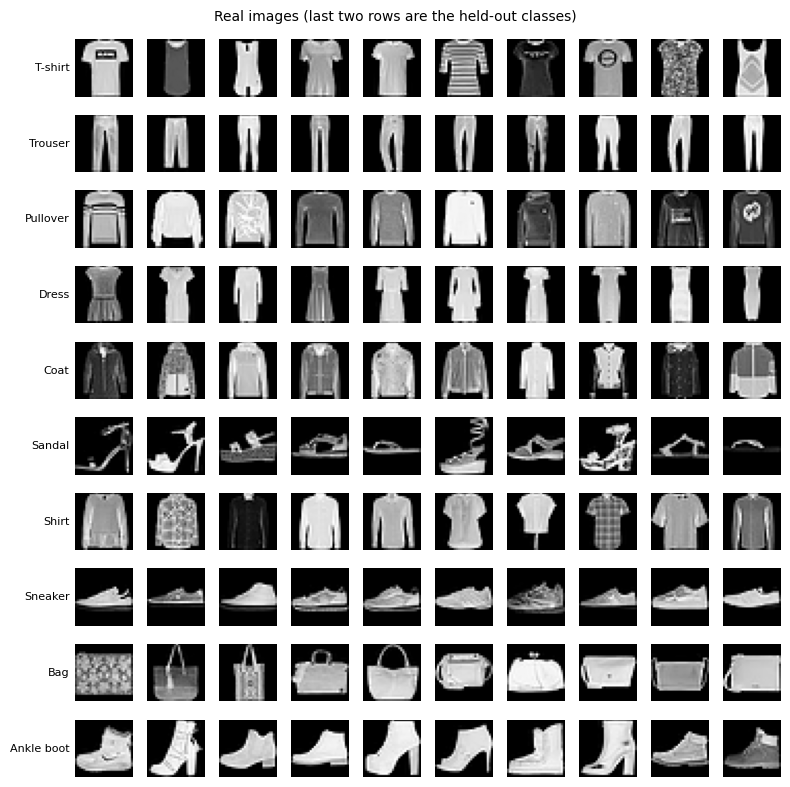

In [2]:
URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = {"xtr": "train-images-idx3-ubyte.gz", "ytr": "train-labels-idx1-ubyte.gz",
         "xte": "t10k-images-idx3-ubyte.gz", "yte": "t10k-labels-idx1-ubyte.gz"}


def read_idx(path):
    raw = gzip.open(path).read()
    if int.from_bytes(raw[:4], "big") == 2051:  # images
        n, r, c = (int.from_bytes(raw[i:i + 4], "big") for i in (4, 8, 12))
        return np.frombuffer(raw, np.uint8, offset=16).reshape(n, r, c)
    return np.frombuffer(raw, np.uint8, offset=8)  # labels


arr = {}
for k, f in FILES.items():
    p = DATA / f
    if not p.exists():
        urllib.request.urlretrieve(URL + f, p)
    arr[k] = read_idx(p)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
BASE, NEW = list(range(8)), [8, 9]
NULL = 10  # extra embedding row for the unconditional branch of classifier-free guidance

to_tensor = lambda a: torch.from_numpy(a.copy()).float().div(127.5).sub(1).unsqueeze(1)  # scale to [-1, 1]
Xtr, Ytr = to_tensor(arr["xtr"]), torch.from_numpy(arr["ytr"].astype(np.int64))
Xte, Yte = to_tensor(arr["xte"]), torch.from_numpy(arr["yte"].astype(np.int64))
ytrain, ytest = Ytr.numpy(), Yte.numpy()
base_mask = torch.from_numpy(np.isin(ytrain, BASE))
print(f"train {tuple(Xtr.shape)}, test {tuple(Xte.shape)}; pretraining uses {int(base_mask.sum())} images of classes 0-7")


def show_grid(x, ncol=10, title=None, path=None, row_labels=None):
    x = (x.detach().float().cpu().clamp(-1, 1) + 1) / 2
    nrow = math.ceil(len(x) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 0.8, nrow * 0.8))
    axes = np.array(axes).reshape(nrow, ncol)
    for i, ax in enumerate(axes.reshape(-1)):
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        if i < len(x):
            ax.imshow(x[i, 0], cmap="gray", vmin=0, vmax=1)
    if row_labels:
        for r, lab in enumerate(row_labels[:nrow]):
            axes[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()


idx = torch.cat([torch.where(Ytr == c)[0][:10] for c in range(10)])
show_grid(Xtr[idx], title="Real images (last two rows are the held-out classes)", row_labels=CLASSES)

## 1. The measuring stick

Inception-based FID makes little sense for 28×28 grayscale clothing, so I train a small CNN on all ten classes and use it twice: its 128-d penultimate features for **FID** and **KID**, and its predictions for **class accuracy** (is a sample generated for "Coat" classified as a coat?). KID is unbiased, so it is the safer number when sample sizes are small. Before trusting the metrics I check that real-vs-real gives a small FID and that FID grows steadily as real images are corrupted.

In [3]:
class FeatureNet(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.body = nn.Sequential(block(1, 32), block(32, 64), nn.Flatten(), nn.Dropout(0.3),
                                  nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)

    def forward(self, x):
        return self.head(self.body(x))

    def features(self, x):
        return self.body(x)


clf = FeatureNet().to(DEVICE)
clf_path = CKPT / "feature_net.pt"
if clf_path.exists():
    clf.load_state_dict(torch.load(clf_path, map_location=DEVICE))
else:
    seed_all(0)
    opt = torch.optim.AdamW(clf.parameters(), 2e-3, weight_decay=1e-4)
    for ep in range(BUDGET["cls_epochs"]):
        clf.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), 256):
            b = perm[i:i + 256]
            x, y = Xtr[b].to(DEVICE), Ytr[b].to(DEVICE)
            x = x + 0.05 * torch.randn_like(x)  # mild noise so the features are not thrown by sampler grain
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    torch.save(clf.state_dict(), clf_path)
clf.eval()


@torch.no_grad()
def batched(fn, x, bs=1000):
    return torch.cat([fn(x[i:i + bs].to(DEVICE)).float().cpu() for i in range(0, len(x), bs)])


test_acc = (batched(clf, Xte).argmax(1) == Yte).float().mean().item()
print(f"feature net, test accuracy: {test_acc:.4f}")


def fid(f1, f2):
    f1, f2 = np.asarray(f1, np.float64), np.asarray(f2, np.float64)
    if not (np.isfinite(f1).all() and np.isfinite(f2).all()):
        return float("nan")
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    eps = np.eye(len(s1)) * 1e-6  # keeps sqrtm stable when a covariance is close to singular
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = (covmean[0] if isinstance(covmean, tuple) else covmean).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))


def kid(f1, f2, n_sub=50, sub=1000, seed=0):
    """Unbiased MMD^2 with the cubic polynomial kernel (Binkowski et al., 2018), reported x1000."""
    rng = np.random.default_rng(seed)
    f1, f2 = np.asarray(f1, np.float64), np.asarray(f2, np.float64)
    d, m, vals = f1.shape[1], min(sub, len(f1), len(f2)), []
    for _ in range(n_sub):
        x = f1[rng.choice(len(f1), m, replace=False)]
        y = f2[rng.choice(len(f2), m, replace=False)]
        kxx, kyy, kxy = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx) + kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals) * 1000)


feats_test = batched(clf.features, Xte).numpy()
real_base = feats_test[np.isin(ytest, BASE)]
real_new = feats_test[np.isin(ytest, NEW)]

# sanity checks on the metrics
rng = np.random.default_rng(0)
n = BUDGET["n_eval"]
pick = rng.choice(np.where(np.isin(ytrain, BASE))[0], n, replace=False)
xb = Xtr[pick]
rows = []
for s in (0.0, 0.05, 0.1, 0.2, 0.4):
    x = (xb + s * torch.randn_like(xb)).clamp(-1, 1)
    f = batched(clf.features, x).numpy()
    rows.append({"real train images (classes 0-7)": "clean" if s == 0 else f"+ N(0, {s}) noise",
                 "FID vs test": fid(f, real_base), "KID x1000": kid(f, real_base)})
sanity = pd.DataFrame(rows).round(2)
NOISE_FLOOR = float(sanity.iloc[0]["FID vs test"])
display(sanity)

feature net, test accuracy: 0.9123


,real train images (classes 0-7),FID vs test,KID x1000
0,clean,4.49,26160.96
1,"+ N(0, 0.05) noise",18.95,48164.95
2,"+ N(0, 0.1) noise",94.93,206421.20
3,"+ N(0, 0.2) noise",361.46,641388.85
4,"+ N(0, 0.4) noise",1021.27,1309198.34


FID rises monotonically with corruption and the clean real-vs-real value is the noise floor for this sample size. Every FID below is computed at the same sample size, so values are comparable with each other (not with Inception FIDs from papers).

## 2. Model and objectives

A compact U-Net: 28 → 14 → 7 resolution, FiLM-style conditioning on time and class, self-attention at 7×7 and in the middle block. The same network is trained twice from the same seed, once per objective:

* **DDPM** (Ho et al., 2020): predict the added noise ε, cosine schedule (Nichol & Dhariwal, 2021), sampled with deterministic DDIM (Song et al., 2021).
* **Flow matching / rectified flow** (Lipman et al., 2023; Liu et al., 2023): predict the velocity *data − noise* along a straight path, with logit-normal time sampling (Esser et al., 2024), sampled with Euler steps.

Both use classifier-free guidance (Ho & Salimans, 2022): the label is dropped 10% of the time during training, and at sampling time `out = uncond + w · (cond − uncond)`, so `w = 1` is plain conditional sampling. With guidance every step costs one forward pass on a doubled batch, so steps = NFE for both samplers.

In [4]:
class SinEmb(nn.Module):
    def __init__(self, d):
        super().__init__(); self.d = d

    def forward(self, t):
        h = self.d // 2
        f = torch.exp(-math.log(10000) * torch.arange(h, device=t.device) / h)
        a = t.float()[:, None] * f[None]
        return torch.cat([a.sin(), a.cos()], -1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, ed):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(ed, 2 * cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x)))
        scale, shift = self.emb(F.silu(e))[:, :, None, None].chunk(2, 1)
        h = self.c2(F.silu(self.n2(h) * (1 + scale) + shift))
        return h + self.skip(x)


class Attention(nn.Module):
    def __init__(self, c, heads=4):
        super().__init__()
        self.norm, self.heads = nn.GroupNorm(8, c), heads
        self.qkv, self.proj = nn.Linear(c, 3 * c), nn.Linear(c, c)

    def forward(self, x):
        b, c, H, W = x.shape
        t = self.norm(x).flatten(2).transpose(1, 2)
        q, k, v = (z.reshape(b, H * W, self.heads, c // self.heads).transpose(1, 2) for z in self.qkv(t).chunk(3, -1))
        o = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(b, H * W, c)
        return x + self.proj(o).transpose(1, 2).reshape(b, c, H, W)


class Block(nn.Module):
    def __init__(self, cin, cout, ed, attn):
        super().__init__()
        self.res = ResBlock(cin, cout, ed)
        self.attn = Attention(cout) if attn else None

    def forward(self, x, e):
        x = self.res(x, e)
        return self.attn(x) if self.attn is not None else x


class Down(nn.Module):
    def __init__(self, c):
        super().__init__(); self.conv = nn.Conv2d(c, c, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Up(nn.Module):
    def __init__(self, c):
        super().__init__(); self.conv = nn.Conv2d(c, c, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class UNet(nn.Module):
    def __init__(self, ch=32, mult=(1, 2, 2), n_res=2, attn_levels=(2,), n_classes=10, ed=128):
        super().__init__()
        self.time = nn.Sequential(SinEmb(ch), nn.Linear(ch, ed), nn.SiLU(), nn.Linear(ed, ed))
        self.label = nn.Embedding(n_classes + 1, ed)
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        chans, skips, cur = [ch * m for m in mult], [ch], ch
        self.down = nn.ModuleList()
        for i, c in enumerate(chans):
            for _ in range(n_res):
                self.down.append(Block(cur, c, ed, i in attn_levels)); cur = c; skips.append(cur)
            if i < len(chans) - 1:
                self.down.append(Down(cur)); skips.append(cur)
        self.mid1, self.mid_attn, self.mid2 = ResBlock(cur, cur, ed), Attention(cur), ResBlock(cur, cur, ed)
        self.up = nn.ModuleList()
        for i, c in reversed(list(enumerate(chans))):
            for _ in range(n_res + 1):
                self.up.append(Block(cur + skips.pop(), c, ed, i in attn_levels)); cur = c
            if i > 0:
                self.up.append(Up(cur))
        self.out = nn.Sequential(nn.GroupNorm(8, cur), nn.SiLU(), nn.Conv2d(cur, 1, 3, padding=1))

    def forward(self, x, t, y):
        e = self.time(t) + self.label(y)
        h = self.inp(x); hs = [h]
        for m in self.down:
            h = m(h, e) if isinstance(m, Block) else m(h)
            hs.append(h)
        h = self.mid2(self.mid_attn(self.mid1(h, e)), e)
        for m in self.up:
            h = m(torch.cat([h, hs.pop()], 1), e) if isinstance(m, Block) else m(h)
        return self.out(h)


print(f"U-Net parameters: {sum(p.numel() for p in UNet().parameters()) / 1e6:.2f} M")

T = 1000


def cosine_abar(T, s=0.008):
    t = torch.linspace(0, T, T + 1, dtype=torch.float64) / T
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
    betas = (1 - (f[1:] / f[0]) / (f[:-1] / f[0])).clamp(max=0.999)
    return torch.cumprod(1 - betas, 0).float()


ABAR = cosine_abar(T).to(DEVICE)


def loss_ddpm(model, x, y):
    t = torch.randint(0, T, (len(x),), device=x.device)
    eps = torch.randn_like(x)
    a = ABAR[t].view(-1, 1, 1, 1)
    with autocast():
        pred = model(a.sqrt() * x + (1 - a).sqrt() * eps, t, y)
    return F.mse_loss(pred.float(), eps)


def loss_fm(model, x, y):
    t = torch.sigmoid(torch.randn(len(x), device=x.device))  # logit-normal(0, 1)
    noise = torch.randn_like(x)
    tt = t.view(-1, 1, 1, 1)
    with autocast():
        pred = model((1 - tt) * noise + tt * x, t * 1000, y)
    return F.mse_loss(pred.float(), x - noise)


LOSSES = {"ddpm": loss_ddpm, "fm": loss_fm}


@torch.no_grad()
def guided(model, x, t, y, w, amp=None):
    with autocast(amp):
        if w == 1.0:
            return model(x, t, y).float()
        out = model(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, torch.full_like(y, NULL)])).float()
    c, u = out.chunk(2)
    return u + w * (c - u)


@torch.no_grad()
def sample(model, kind, labels, steps=16, w=2.0, seed=0, bs=1000, amp=None, channels_last=False):
    """kind='ddpm': DDIM (eta=0) on the cosine schedule; kind='fm': Euler from noise (t=0) to data (t=1)."""
    model.eval()
    g = torch.Generator().manual_seed(seed)
    outs = []
    for i in range(0, len(labels), bs):
        y = labels[i:i + bs].to(DEVICE)
        x = torch.randn(len(y), 1, 28, 28, generator=g).to(DEVICE)
        if channels_last:
            x = x.contiguous(memory_format=torch.channels_last)
        if kind == "ddpm":
            ts = torch.linspace(T - 1, 0, steps).round().long().tolist()
            for j, t in enumerate(ts):
                eps = guided(model, x, torch.full((len(y),), t, device=DEVICE), y, w, amp)
                a = ABAR[t]
                a_prev = ABAR[ts[j + 1]] if j + 1 < len(ts) else torch.ones((), device=DEVICE)
                x0 = ((x - (1 - a).sqrt() * eps) / a.sqrt()).clamp(-1, 1)
                eps = (x - a.sqrt() * x0) / (1 - a).sqrt()
                x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
        else:
            ts = torch.linspace(0, 1, steps + 1).tolist()
            for j in range(steps):
                v = guided(model, x, torch.full((len(y),), ts[j] * 1000, device=DEVICE), y, w, amp)
                x = x + (ts[j + 1] - ts[j]) * v
        outs.append(x.clamp(-1, 1).float().cpu())
    return torch.cat(outs)

U-Net parameters: 1.74 M


## 3. Pretraining on classes 0–7

Same seed, data order, optimizer and budget for both objectives. AdamW (lr 5e-4, 500 warm-up steps), gradient clipping at 1.0, EMA of the weights for sampling, mixed precision. Checkpoints are written every 2,000 steps, so a disconnected session resumes where it stopped.

ddpm: step 2000/10000, loss 0.0885, 2.9 min


ddpm: step 4000/10000, loss 0.0717, 5.8 min


ddpm: step 6000/10000, loss 0.0636, 8.8 min


ddpm: step 8000/10000, loss 0.0652, 11.7 min


ddpm: step 10000/10000, loss 0.0644, 14.6 min


fm: step 2000/10000, loss 0.2204, 2.9 min


fm: step 4000/10000, loss 0.1762, 5.9 min


fm: step 6000/10000, loss 0.1670, 8.8 min


fm: step 8000/10000, loss 0.1645, 11.7 min


fm: step 10000/10000, loss 0.1652, 14.6 min


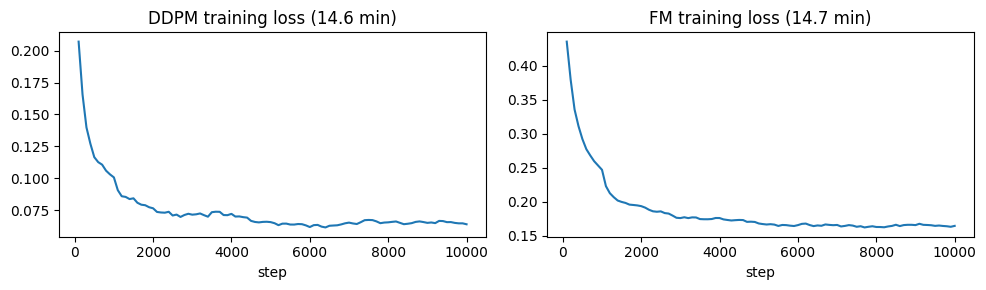

In [5]:
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay, self.shadow = decay, copy.deepcopy(model).eval().requires_grad_(False)

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))  # warm-up so the random init fades quickly
        for e, p in zip(self.shadow.parameters(), model.parameters()):
            e.lerp_(p.detach(), 1 - d)


def pretrain(kind):
    path = CKPT / f"base_{kind}.pt"
    total, bs = BUDGET["pretrain_steps"], BUDGET["batch"]
    seed_all(0)
    model = UNet().to(DEVICE)
    ema = EMA(model)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda", enabled=GPU)
    step, log, secs = 0, [], 0.0
    if path.exists():
        ck = torch.load(path, map_location=DEVICE)
        model.load_state_dict(ck["model"]); ema.shadow.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        step, log, secs = ck["step"], ck["log"], ck["secs"]
        if step >= total:
            print(f"{kind}: loaded finished run ({step} steps, {secs / 60:.1f} min)")
            return ema.shadow, log, secs
        print(f"{kind}: resuming at step {step}")
    Xb, Yb = Xtr[base_mask].to(DEVICE), Ytr[base_mask].to(DEVICE)
    g = torch.Generator(device=DEVICE).manual_seed(1000 + step)
    model.train()
    t0 = time.time()
    while step < total:
        idx = torch.randint(0, len(Xb), (bs,), device=DEVICE, generator=g)
        x, y = Xb[idx], Yb[idx]
        y = torch.where(torch.rand(bs, device=DEVICE, generator=g) < 0.1, torch.full_like(y, NULL), y)
        for gp in opt.param_groups:
            gp["lr"] = 5e-4 * min(1.0, (step + 1) / 500)
        loss = LOSSES[kind](model, x, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        ema.update(model, step)
        step += 1
        if step % 100 == 0 or step == total:
            log.append((step, loss.item()))
        if step % 2000 == 0 or step == total:
            sync()
            secs_now = secs + time.time() - t0
            torch.save(dict(model=model.state_dict(), ema=ema.shadow.state_dict(), opt=opt.state_dict(),
                            scaler=scaler.state_dict(), step=step, log=log, secs=secs_now), path)
            print(f"{kind}: step {step}/{total}, loss {np.mean([l for _, l in log[-20:]]):.4f}, {secs_now / 60:.1f} min")
    sync()
    return ema.shadow, log, secs + time.time() - t0


models, train_logs, train_secs = {}, {}, {}
for kind in ("ddpm", "fm"):
    models[kind], train_logs[kind], train_secs[kind] = pretrain(kind)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, kind in zip(ax, ("ddpm", "fm")):
    s, l = zip(*train_logs[kind])
    a.plot(s, pd.Series(l).rolling(10, min_periods=1).mean())
    a.set_title(f"{kind.upper()} training loss ({train_secs[kind] / 60:.1f} min)"); a.set_xlabel("step")
plt.tight_layout(); fig.savefig(FIG / "training_loss.png", dpi=130); plt.show()

## Experiment 1: sampling budget and guidance

Each configuration generates `n_eval` images (equal numbers per class) with two sampling seeds. Lower FID/KID is better; class accuracy is the share of samples the feature net assigns to the requested class.

fid                  kid                acc       
kind      ddpm       fm        ddpm          fm   ddpm     fm
steps                                                        
4      204.884  157.892  407076.260  618625.323  0.833  0.967
8       75.335  111.078  206387.749  461824.642  0.950  0.975
16      60.597   84.416  214097.255  343099.516  0.967  0.979
32      51.405   68.456  186919.363  266762.438  0.972  0.981
64      45.542   60.800  160965.700  227595.453  0.974  0.981

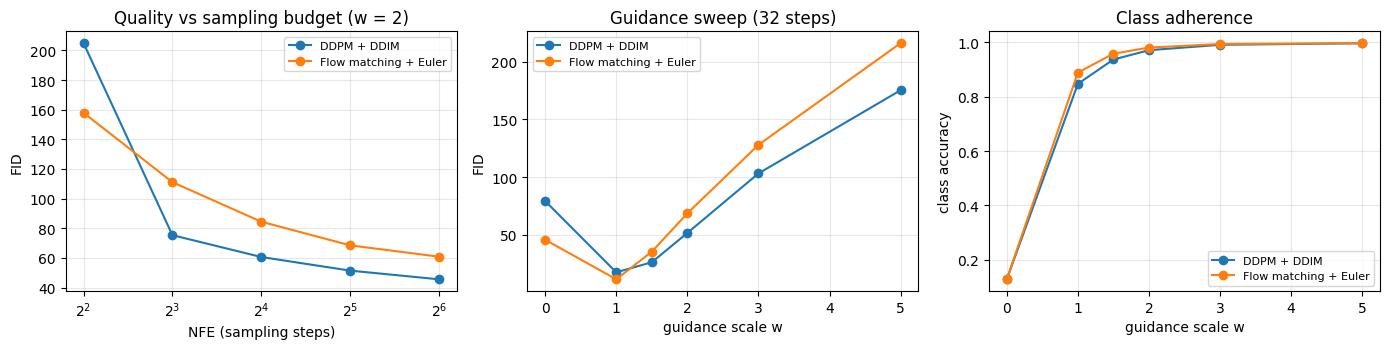

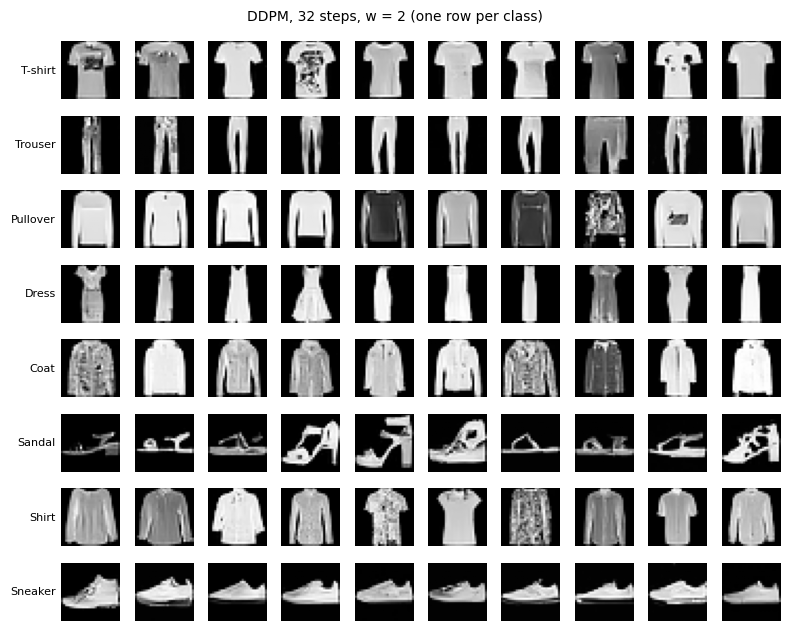

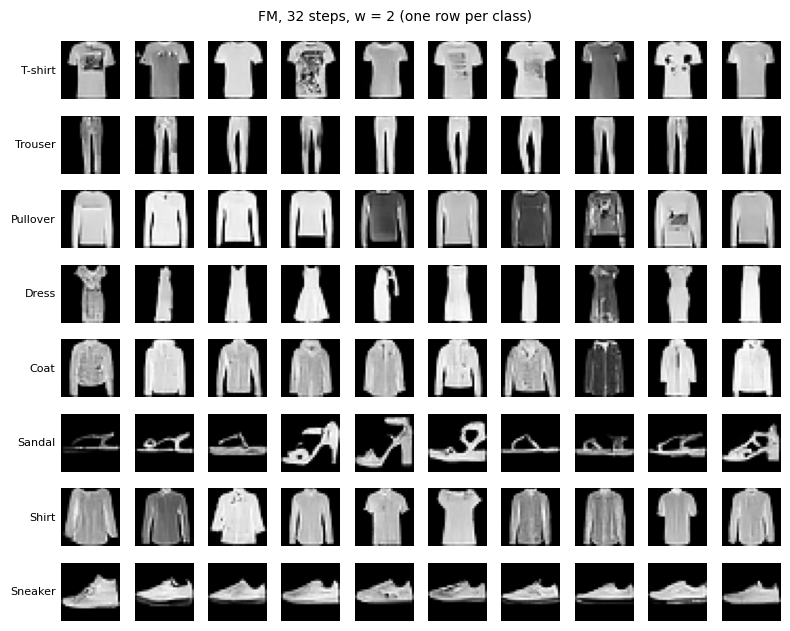

At 32 steps and w = 2: DDPM FID 51.40, flow matching FID 68.46. Experiments 2 and 3 use the DDPM model.


In [6]:
def per_class_labels(classes, n):
    return torch.tensor(classes).repeat_interleave(max(1, n // len(classes)))


LAB_BASE = per_class_labels(BASE, BUDGET["n_eval"])
LAB_NEW = per_class_labels(NEW, BUDGET["n_eval"] // 2)


def evaluate(images, labels, real_feats):
    bad = int((~torch.isfinite(images)).flatten(1).any(1).sum())  # diverged samples, if any, are counted and zeroed
    images = torch.nan_to_num(images, nan=0.0, posinf=1.0, neginf=-1.0)
    f = batched(clf.features, images).numpy()
    acc = (batched(clf, images).argmax(1) == labels).float().mean().item()
    return dict(fid=fid(f, real_feats), kid=kid(f, real_feats), acc=acc, nonfinite=bad)


exp1_path = RES / "exp1_sampling.json"
exp1 = load_json(exp1_path, {})
SAMPLE_SEEDS = [0, 1] if MODE != "SMOKE" else [0]
REF = BUDGET["ref_steps"]
configs = [(k, s, 2.0) for k in ("ddpm", "fm") for s in BUDGET["nfe"]]
configs += [(k, REF, w) for k in ("ddpm", "fm") for w in (0.0, 1.0, 1.5, 3.0, 5.0)]
for kind, steps, w in configs:
    for sd in SAMPLE_SEEDS:
        key = f"{kind}|{steps}|{w}|{sd}"
        if key in exp1:
            continue
        sync(); t0 = time.time()
        imgs = sample(models[kind], kind, LAB_BASE, steps=steps, w=w, seed=sd)
        sync(); dt = time.time() - t0
        exp1[key] = dict(kind=kind, steps=steps, w=w, seed=sd, ms_per_img=1000 * dt / len(LAB_BASE),
                         **evaluate(imgs, LAB_BASE, real_base))
        save_json(exp1, exp1_path)

e1 = pd.DataFrame(exp1.values())
e1 = e1.groupby(["kind", "steps", "w"]).agg(fid=("fid", "mean"), fid_sd=("fid", "std"), kid=("kid", "mean"),
                                            acc=("acc", "mean"), ms_per_img=("ms_per_img", "mean")).reset_index()
display(e1[e1.w == 2.0].pivot(index="steps", columns="kind", values=["fid", "kid", "acc"]).round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for kind, lab in (("ddpm", "DDPM + DDIM"), ("fm", "Flow matching + Euler")):
    d = e1[(e1.kind == kind) & (e1.w == 2.0)].sort_values("steps")
    ax[0].plot(d.steps, d.fid, "o-", label=lab)
    g_ = e1[(e1.kind == kind) & (e1.steps == REF)].sort_values("w")
    ax[1].plot(g_.w, g_.fid, "o-", label=lab)
    ax[2].plot(g_.w, g_.acc, "o-", label=lab)
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("NFE (sampling steps)"); ax[0].set_ylabel("FID"); ax[0].set_title("Quality vs sampling budget (w = 2)")
ax[1].set_xlabel("guidance scale w"); ax[1].set_ylabel("FID"); ax[1].set_title(f"Guidance sweep ({REF} steps)")
ax[2].set_xlabel("guidance scale w"); ax[2].set_ylabel("class accuracy"); ax[2].set_title("Class adherence")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "exp1_nfe_guidance.png", dpi=130); plt.show()

for kind in ("ddpm", "fm"):
    grid = sample(models[kind], kind, per_class_labels(BASE, 80), steps=REF, w=2.0, seed=123)
    show_grid(grid, title=f"{kind.upper()}, {REF} steps, w = 2 (one row per class)", path=FIG / f"samples_{kind}.png",
              row_labels=CLASSES[:8])

ref = e1[(e1.steps == REF) & (e1.w == 2.0)].set_index("kind")
CARRY = ref.fid.idxmin()
print(f"At {REF} steps and w = 2: DDPM FID {ref.fid['ddpm']:.2f}, flow matching FID {ref.fid['fm']:.2f}. "
      f"Experiments 2 and 3 use the {CARRY.upper()} model.")

## Experiment 2: teaching the model two new classes from 200 images each

Starting from the better pretrained model, each method learns *Bag* and *Ankle boot* from `k_shot` images per class (a different random subset for every seed). The new class embeddings start at the mean of the eight known embeddings.

| Method | What is trained |
|---|---|
| Embedding only | the two new class-embedding rows (the textual-inversion idea, Gal et al., 2023) |
| LoRA r = 4 / r = 16 | low-rank adapters on every `Conv2d` and `Linear` outside the time MLP, plus the two embedding rows (Hu et al., 2022) |
| Full fine-tuning | every weight |

Classifier-free label dropout is off during adaptation, learning rates follow common practice for each method (full 1e-4, LoRA 1e-3, embedding 1e-2), and no images of the old classes are replayed. After training I measure quality on the new classes and how far quality on the **old** classes moved (forgetting).

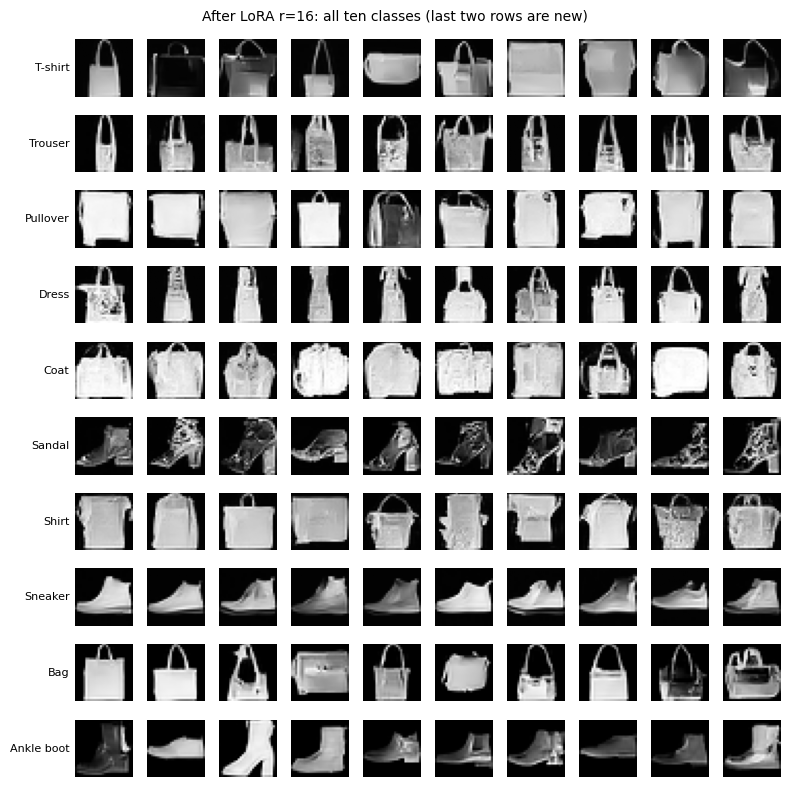

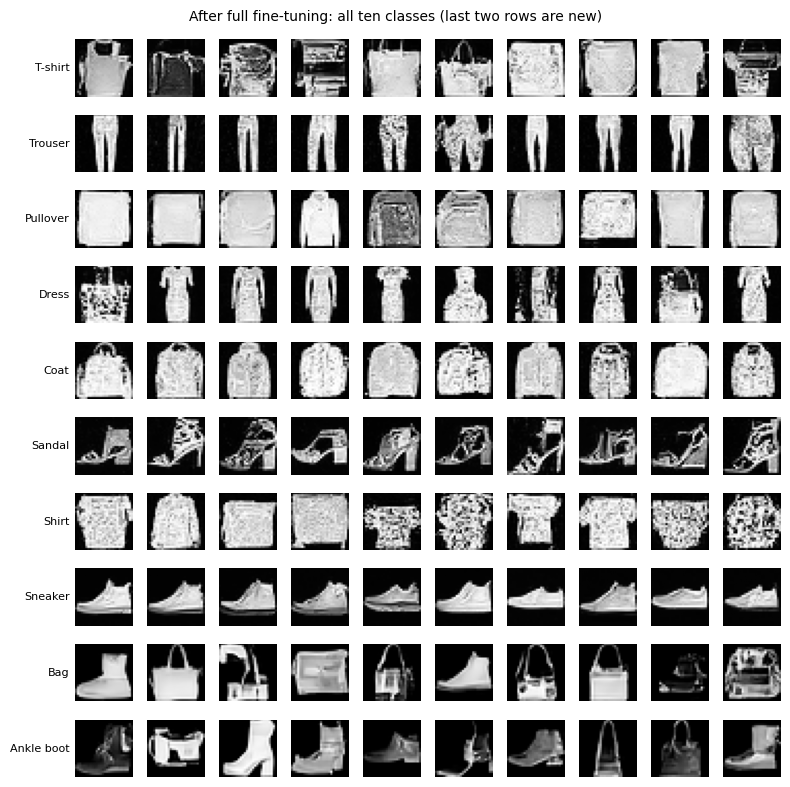

Before adaptation: new-class FID 2497.7, new-class accuracy 0.067; old-class FID 49.21, old-class accuracy 0.970


,method,trainable params,adapter MB (fp16),train s,new FID,± new FID,new acc,old FID,± old FID,old acc,forgetting (ΔFID old)
0,emb,256,0.000,53.831,989.200,35.152,0.451,49.211,0.000,0.970,-0.000
1,lora4,132392,0.253,117.997,113.023,103.559,0.913,881.488,214.613,0.366,832.277
2,lora16,528800,1.009,115.898,119.419,98.949,0.908,1213.324,281.064,0.261,1164.113
3,full,1744289,3.327,82.160,367.692,436.471,0.546,448.386,32.360,0.624,399.175


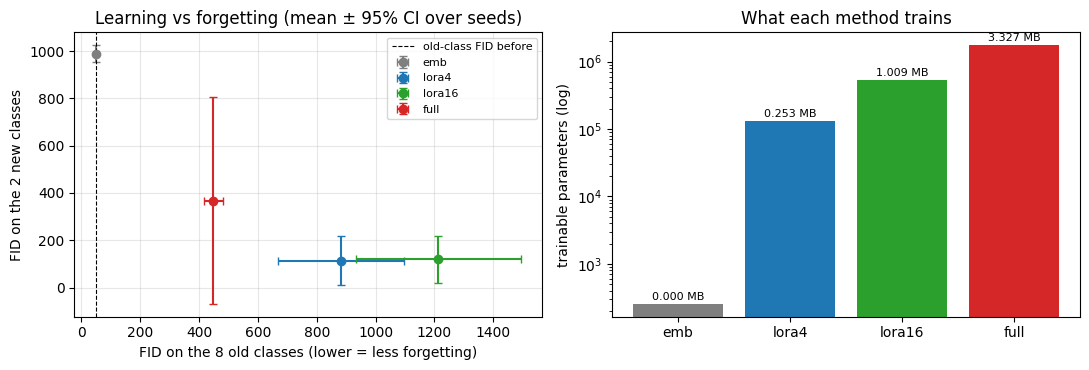

LoRA r=16 minus full FT, mean over 3 paired seeds: new-class FID -248.27 (±338.22), old-class FID +764.94 (±312.48)


In [7]:
class LoRALinear(nn.Module):
    def __init__(self, base, r):
        super().__init__()
        self.base, self.r, self.merged = base, r, False
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=base.weight.device))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=base.weight.device))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        y = self.base(x)
        return y if self.merged else y + (x @ self.A.t().to(x.dtype)) @ self.B.t().to(x.dtype)

    @torch.no_grad()
    def merge(self):
        self.base.weight += self.B @ self.A
        self.merged = True


class LoRAConv(nn.Module):
    def __init__(self, base, r):
        super().__init__()
        self.base, self.r, self.merged = base, r, False
        dev = base.weight.device
        self.A = nn.Conv2d(base.in_channels, r, base.kernel_size, base.stride, base.padding, bias=False).to(dev)
        self.B = nn.Conv2d(r, base.out_channels, 1, bias=False).to(dev)
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5)); nn.init.zeros_(self.B.weight)

    def forward(self, x):
        y = self.base(x)
        return y if self.merged else y + self.B(self.A(x))

    @torch.no_grad()
    def merge(self):
        self.base.weight += torch.einsum("or,rikl->oikl", self.B.weight[:, :, 0, 0], self.A.weight)
        self.merged = True


def add_lora(model, r):
    todo = [(parent, name, child) for pname, parent in model.named_modules() if not pname.startswith("time")
            for name, child in parent.named_children() if isinstance(child, (nn.Linear, nn.Conv2d))]
    for parent, name, child in todo:
        setattr(parent, name, LoRALinear(child, r) if isinstance(child, nn.Linear) else LoRAConv(child, r))
    return len(todo)


def merge_lora(model):
    for m in model.modules():
        if isinstance(m, (LoRALinear, LoRAConv)):
            m.merge()
    return model


def adapt(base_model, kind, method, seed):
    seed_all(seed)
    m = copy.deepcopy(base_model).train()
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(ytrain == c)[0], BUDGET["k_shot"], replace=False) for c in NEW])
    Xa, Ya = Xtr[idx].to(DEVICE), Ytr[idx].to(DEVICE)
    ed = m.label.weight.shape[1]
    with torch.no_grad():
        m.label.weight[NEW] = m.label.weight[BASE].mean(0, keepdim=True) + 0.01 * torch.randn(len(NEW), ed, device=DEVICE)
    if method == "full":
        m.requires_grad_(True)
        lr = 1e-4
        n_trainable = sum(p.numel() for p in m.parameters())
    else:
        m.requires_grad_(False)
        n_layers = add_lora(m, int(method[4:])) if method.startswith("lora") else 0
        mask = torch.zeros_like(m.label.weight); mask[NEW] = 1
        m.label.weight.requires_grad_(True)
        m.label.weight.register_hook(lambda g: g * mask)
        lr = 1e-3 if method.startswith("lora") else 1e-2
        n_trainable = sum(p.numel() for n_, p in m.named_parameters() if p.requires_grad and not n_.startswith("label")) + len(NEW) * ed
    params = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda", enabled=GPU)
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    sync(); t0 = time.time()
    for step in range(BUDGET["adapt_steps"]):
        b = torch.randint(0, len(Xa), (64,), device=DEVICE, generator=g)
        loss = LOSSES[kind](m, Xa[b], Ya[b])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update()
    sync()
    m.eval().requires_grad_(False)
    return m, dict(trainable=n_trainable, adapter_mb=n_trainable * 2 / 2**20, train_s=time.time() - t0)


exp2_path = RES / "exp2_adaptation.json"
exp2 = load_json(exp2_path, {})
base_model = models[CARRY]
steps2, w2 = REF, 2.0

if "before" not in exp2:  # the pretrained model asked for the new classes with mean-initialised embeddings
    m0 = copy.deepcopy(base_model)
    with torch.no_grad():
        m0.label.weight[NEW] = m0.label.weight[BASE].mean(0, keepdim=True)
    exp2["before"] = dict(method="before", seed=0, trainable=0, adapter_mb=0, train_s=0,
                          **{f"new_{k}": v for k, v in evaluate(sample(m0, CARRY, LAB_NEW, steps2, w2, seed=7), LAB_NEW, real_new).items()},
                          **{f"old_{k}": v for k, v in evaluate(sample(base_model, CARRY, LAB_BASE, steps2, w2, seed=7), LAB_BASE, real_base).items()})
    save_json(exp2, exp2_path)

METHODS = ["emb", "lora4", "lora16", "full"]
for method in METHODS:
    for seed in BUDGET["seeds"]:
        key = f"{method}|{seed}"
        if key in exp2:
            continue
        m, info = adapt(base_model, CARRY, method, seed)
        new = evaluate(sample(m, CARRY, LAB_NEW, steps2, w2, seed=7), LAB_NEW, real_new)
        old = evaluate(sample(m, CARRY, LAB_BASE, steps2, w2, seed=7), LAB_BASE, real_base)
        exp2[key] = dict(method=method, seed=seed, **info, **{f"new_{k}": v for k, v in new.items()},
                         **{f"old_{k}": v for k, v in old.items()})
        save_json(exp2, exp2_path)
        if method == "lora16" and seed == BUDGET["seeds"][0]:
            torch.save(m.state_dict(), CKPT / "adapted_lora16.pt")
            show_grid(sample(m, CARRY, per_class_labels(list(range(10)), 100), steps2, w2, seed=11),
                      title="After LoRA r=16: all ten classes (last two rows are new)", path=FIG / "samples_lora16.png",
                      row_labels=CLASSES)
        if method == "full" and seed == BUDGET["seeds"][0]:
            show_grid(sample(m, CARRY, per_class_labels(list(range(10)), 100), steps2, w2, seed=11),
                      title="After full fine-tuning: all ten classes (last two rows are new)", path=FIG / "samples_full.png",
                      row_labels=CLASSES)

e2 = pd.DataFrame([v for k, v in exp2.items() if k != "before"])
before = exp2["before"]


def ci95(x):
    x = np.asarray(x, float)
    if len(x) < 2:
        return 0.0
    from scipy import stats
    return float(stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)))


summary2 = []
for method in METHODS:
    d = e2[e2.method == method]
    summary2.append({"method": method, "trainable params": int(d.trainable.iloc[0]), "adapter MB (fp16)": d.adapter_mb.iloc[0],
                     "train s": d.train_s.mean(),
                     "new FID": d.new_fid.mean(), "± new FID": ci95(d.new_fid), "new acc": d.new_acc.mean(),
                     "old FID": d.old_fid.mean(), "± old FID": ci95(d.old_fid), "old acc": d.old_acc.mean(),
                     "forgetting (ΔFID old)": d.old_fid.mean() - before["old_fid"]})
summary2 = pd.DataFrame(summary2)
print(f"Before adaptation: new-class FID {before['new_fid']:.1f}, new-class accuracy {before['new_acc']:.3f}; "
      f"old-class FID {before['old_fid']:.2f}, old-class accuracy {before['old_acc']:.3f}")
display(summary2.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"emb": "#7f7f7f", "lora4": "#1f77b4", "lora16": "#2ca02c", "full": "#d62728"}
for method in METHODS:
    d = e2[e2.method == method]
    ax[0].errorbar(d.old_fid.mean(), d.new_fid.mean(), xerr=ci95(d.old_fid), yerr=ci95(d.new_fid), fmt="o",
                   color=colors[method], label=method, capsize=3)
ax[0].axvline(before["old_fid"], ls="--", c="k", lw=0.8, label="old-class FID before")
ax[0].set_xlabel("FID on the 8 old classes (lower = less forgetting)"); ax[0].set_ylabel("FID on the 2 new classes")
ax[0].set_title("Learning vs forgetting (mean ± 95% CI over seeds)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].bar(summary2.method, summary2["trainable params"], color=[colors[m] for m in summary2.method])
ax[1].set_yscale("log"); ax[1].set_ylabel("trainable parameters (log)"); ax[1].set_title("What each method trains")
for i, v in enumerate(summary2["adapter MB (fp16)"]):
    ax[1].text(i, summary2["trainable params"].iloc[i] * 1.15, f"{v:.3f} MB", ha="center", fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "exp2_learning_vs_forgetting.png", dpi=130); plt.show()

# paired comparison across seeds (same data subset per seed): LoRA r=16 vs full fine-tuning
from scipy import stats
pv = e2.pivot(index="seed", columns="method", values=["new_fid", "old_fid"])
d_new = (pv["new_fid"]["lora16"] - pv["new_fid"]["full"]).values
d_old = (pv["old_fid"]["lora16"] - pv["old_fid"]["full"]).values
print(f"LoRA r=16 minus full FT, mean over {len(d_new)} paired seeds: new-class FID {d_new.mean():+.2f} (±{ci95(d_new):.2f}), "
      f"old-class FID {d_old.mean():+.2f} (±{ci95(d_old):.2f})")

## Experiment 3: inference cost

Same model, sampler and settings as above (`ref_steps` steps, w = 2, so every step is a forward pass on a doubled batch). Latency is the median of repeated timed runs after warm-up; the GPU is synchronised before every clock read. Mixed precision and compilation are only worth keeping if they leave the samples unchanged, so I check FID and class accuracy for each variant on the same noise seeds.

W1125 00:52:32.217000 22892 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


,ms_per_img,img_per_s,peak_mem_mb,fid,kid,acc,nonfinite,max_abs_pixel_diff_vs_fp32,mean_abs_pixel_diff_vs_fp32,compile_s,speed-up vs fp32
fp32,18.410,54.317,1056.829,45.904,153320.324,0.967,0.0,0.000,0.000,NaN,1.000
float16 autocast,13.675,73.126,591.966,46.157,153814.800,0.966,0.0,1.798,0.004,NaN,1.346
autocast + channels_last,15.663,63.844,692.266,46.062,152928.040,0.967,0.0,1.799,0.004,NaN,1.175
torch.compile (default) + autocast,5.039,198.443,350.750,46.181,154133.978,0.967,0.0,1.785,0.003,66.145,3.653
torch.compile (reduce-overhead) + autocast,6.326,158.074,66.076,46.088,153468.967,0.966,0.0,1.800,0.003,36.721,2.910


,batch,latency_s,img_per_s
0,1,0.779,1.284
1,8,0.613,13.046
2,32,0.618,51.797
3,128,1.689,75.791
4,512,6.710,76.301


LoRA r=16, ms per image: unmerged 19.456, merged 13.503; max |difference| between outputs 1.61e-02


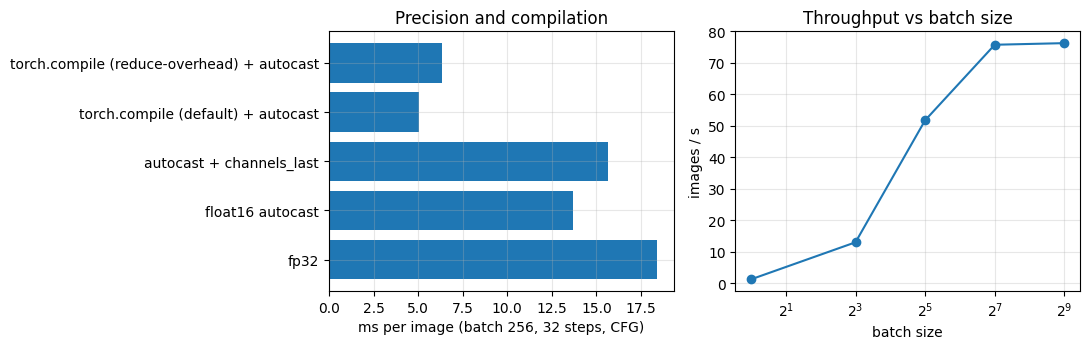

In [8]:
def time_gen(model, n, steps, reps=5, **kw):
    labels = per_class_labels(BASE, n)[:n]
    for _ in range(2):
        sample(model, CARRY, labels, steps=steps, w=2.0, seed=0, bs=n, **kw)
    ts = []
    for _ in range(reps):
        sync(); t0 = time.time()
        sample(model, CARRY, labels, steps=steps, w=2.0, seed=0, bs=n, **kw)
        sync(); ts.append(time.time() - t0)
    return float(np.median(ts))


exp3_path = RES / "exp3_inference.json"
exp3 = load_json(exp3_path, {})
BS = 256 if MODE != "SMOKE" else 16
m_fp32 = copy.deepcopy(models[CARRY]).float().eval()

variants = {"fp32": dict(model=m_fp32, amp=False)}
if USE_AMP:
    variants[f"{str(AMP_DTYPE).split('.')[-1]} autocast"] = dict(model=m_fp32, amp=True)
    m_cl = copy.deepcopy(m_fp32).to(memory_format=torch.channels_last)
    variants["autocast + channels_last"] = dict(model=m_cl, amp=True, channels_last=True)
for mode_ in (["default", "reduce-overhead"] if GPU else ["default"]):
    variants[f"torch.compile ({mode_})" + (" + autocast" if USE_AMP else "")] = dict(compile=mode_, amp=USE_AMP)

for name, v in variants.items():
    if name in exp3:
        continue
    model = v.get("model")
    rec = {}
    try:
        if "compile" in v:
            sync(); t0 = time.time()
            model = torch.compile(copy.deepcopy(m_fp32), mode=v["compile"])
            sample(model, CARRY, per_class_labels(BASE, BS)[:BS], steps=REF, w=2.0, bs=BS, amp=v["amp"])  # triggers compilation
            sync(); rec["compile_s"] = time.time() - t0
        if GPU:
            torch.cuda.reset_peak_memory_stats()
        sec = time_gen(model, BS, REF, amp=v["amp"], channels_last=v.get("channels_last", False))
        rec.update(ms_per_img=1000 * sec / BS, img_per_s=BS / sec,
                   peak_mem_mb=torch.cuda.max_memory_allocated() / 2**20 if GPU else None)
        imgs = sample(model, CARRY, LAB_BASE, steps=REF, w=2.0, seed=5, bs=BS, amp=v["amp"],
                      channels_last=v.get("channels_last", False))
        rec.update(**evaluate(imgs, LAB_BASE, real_base))
        if name == "fp32":
            torch.save(imgs, RES / "fp32_reference_samples.pt")
        ref_imgs = torch.load(RES / "fp32_reference_samples.pt")
        rec["max_abs_pixel_diff_vs_fp32"] = float((imgs - ref_imgs).abs().max())
        rec["mean_abs_pixel_diff_vs_fp32"] = float((imgs - ref_imgs).abs().mean())
    except Exception as e:
        rec["error"] = repr(e)[:300]
    exp3[name] = rec
    save_json(exp3, exp3_path)

e3 = pd.DataFrame(exp3).T
e3["speed-up vs fp32"] = e3["ms_per_img"].astype(float).rdiv(float(e3.loc["fp32", "ms_per_img"]))
display(e3.drop(columns=[c for c in ["error"] if c in e3 and e3[c].isna().all()]).round(3))

# batch size: latency per call vs throughput (best non-compiled setting)
bs_key = "batch_sweep"
if bs_key not in exp3:
    rows = []
    for n in ([1, 8, 32, 128, 512] if GPU else [1, 8, 32, 128]) if MODE != "SMOKE" else [1, 4]:
        sec = time_gen(m_fp32, n, REF, reps=3, amp=USE_AMP)
        rows.append(dict(batch=n, latency_s=sec, img_per_s=n / sec))
    exp3[bs_key] = rows
    save_json(exp3, exp3_path)
bsw = pd.DataFrame(exp3[bs_key])
display(bsw.round(3))

# LoRA: unmerged adapters vs weights merged into the base model
lora_key = "lora_merge"
if lora_key not in exp3 and (CKPT / "adapted_lora16.pt").exists():
    ml = copy.deepcopy(models[CARRY]); add_lora(ml, 16); ml.load_state_dict(torch.load(CKPT / "adapted_lora16.pt", map_location=DEVICE))
    ml.eval()
    t_unmerged = time_gen(ml, BS, REF, amp=USE_AMP)
    out_unmerged = sample(ml, CARRY, LAB_NEW[:BS], steps=REF, w=2.0, seed=3, bs=BS, amp=False)
    merge_lora(ml)
    t_merged = time_gen(ml, BS, REF, amp=USE_AMP)
    out_merged = sample(ml, CARRY, LAB_NEW[:BS], steps=REF, w=2.0, seed=3, bs=BS, amp=False)
    exp3[lora_key] = dict(unmerged_ms_per_img=1000 * t_unmerged / BS, merged_ms_per_img=1000 * t_merged / BS,
                          max_abs_diff=float((out_unmerged - out_merged).abs().max()))
    save_json(exp3, exp3_path)
if lora_key in exp3:
    print("LoRA r=16, ms per image: unmerged {unmerged_ms_per_img:.3f}, merged {merged_ms_per_img:.3f}; "
          "max |difference| between outputs {max_abs_diff:.2e}".format(**exp3[lora_key]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ok = e3[e3["ms_per_img"].notna()]
ax[0].barh(ok.index, ok["ms_per_img"].astype(float), color="#1f77b4")
ax[0].set_xlabel(f"ms per image (batch {BS}, {REF} steps, CFG)"); ax[0].set_title("Precision and compilation")
ax[1].plot(bsw.batch, bsw.img_per_s, "o-")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("batch size"); ax[1].set_ylabel("images / s"); ax[1].set_title("Throughput vs batch size")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / "exp3_inference.png", dpi=130); plt.show()

## Findings

The cell below writes the findings from the saved results, so the text always matches the numbers in this run.

In [9]:
from IPython.display import Markdown

r = e1.set_index(["kind", "steps", "w"])
nfe = BUDGET["nfe"]
lo, hi = nfe[0], nfe[-1]
best_amp = e3.drop(index="fp32")
best_amp = best_amp[best_amp["ms_per_img"].notna()]
best_name = best_amp["ms_per_img"].astype(float).idxmin() if len(best_amp) else "fp32"
s2 = summary2.set_index("method")
lines = [
    f"**Setup.** {env['gpu'] or 'CPU'}, mode {MODE}; U-Net with {sum(p.numel() for p in UNet().parameters()) / 1e6:.2f} M parameters, "
    f"{BUDGET['pretrain_steps']:,} pretraining steps per objective ({train_secs['ddpm'] / 60:.1f} min DDPM, {train_secs['fm'] / 60:.1f} min flow matching); "
    f"{len(LAB_BASE):,} samples per evaluation; FID noise floor (real vs real) {NOISE_FLOOR:.2f}.",
    f"**1. Objective and sampling budget.** At {lo} steps (w = 2) FID is {r.loc[('ddpm', lo, 2.0), 'fid']:.2f} for DDPM+DDIM and "
    f"{r.loc[('fm', lo, 2.0), 'fid']:.2f} for flow matching+Euler; at {hi} steps {r.loc[('ddpm', hi, 2.0), 'fid']:.2f} vs {r.loc[('fm', hi, 2.0), 'fid']:.2f}. "
    f"Guidance raises class accuracy from {r.loc[(CARRY, REF, 0.0), 'acc']:.3f} (w = 0) to {r.loc[(CARRY, REF, 5.0), 'acc']:.3f} (w = 5) for the "
    f"{CARRY.upper()} model, while FID is lowest at w = {e1[(e1.kind == CARRY) & (e1.steps == REF)].set_index('w').fid.idxmin():g}.",
    f"**2. New concepts.** Full fine-tuning reached new-class FID {s2.loc['full', 'new FID']:.2f} but moved old-class FID by "
    f"{s2.loc['full', 'forgetting (ΔFID old)']:+.2f}; LoRA r=16 reached {s2.loc['lora16', 'new FID']:.2f} with {s2.loc['lora16', 'forgetting (ΔFID old)']:+.2f} "
    f"forgetting while training {s2.loc['lora16', 'trainable params'] / s2.loc['full', 'trainable params']:.1%} of the parameters "
    f"({s2.loc['lora16', 'adapter MB (fp16)']:.2f} MB adapter); LoRA r=4: {s2.loc['lora4', 'new FID']:.2f} / {s2.loc['lora4', 'forgetting (ΔFID old)']:+.2f}; "
    f"embedding only: {s2.loc['emb', 'new FID']:.2f} / {s2.loc['emb', 'forgetting (ΔFID old)']:+.2f} (before adaptation the new-class FID was {before['new_fid']:.1f}).",
    f"**3. Inference.** Fastest setting: {best_name}, {float(e3.loc[best_name, 'speed-up vs fp32']):.2f}x faster than fp32 at batch {BS} "
    f"(FID {float(e3.loc[best_name, 'fid']):.2f} vs {float(e3.loc['fp32', 'fid']):.2f} for fp32, mean |pixel difference| "
    f"{float(e3.loc[best_name, 'mean_abs_pixel_diff_vs_fp32']):.4f}). Throughput grows from {bsw.img_per_s.iloc[0]:.0f} img/s at batch 1 to "
    f"{bsw.img_per_s.max():.0f} img/s at batch {int(bsw.loc[bsw.img_per_s.idxmax(), 'batch'])}.",
]
if lora_key in exp3:
    lm = exp3[lora_key]
    lines.append(f"Merging the LoRA weights removes the adapter overhead ({lm['unmerged_ms_per_img']:.3f} → {lm['merged_ms_per_img']:.3f} ms per image) "
                 f"with outputs identical up to {lm['max_abs_diff']:.1e}.")
summary_md = "\n\n".join(lines)
(RES / "findings.md").write_text(summary_md)
save_json(dict(env=env, budget=BUDGET, exp1=e1.to_dict("records"), exp2=summary2.to_dict("records"), before=before,
               exp3={k: v for k, v in exp3.items()}), RES / "summary.json")
display(Markdown(summary_md))

**Setup.** Tesla T4, mode FULL; U-Net with 1.74 M parameters, 10,000 pretraining steps per objective (14.6 min DDPM, 14.7 min flow matching); 4,000 samples per evaluation; FID noise floor (real vs real) 4.49.

**1. Objective and sampling budget.** At 4 steps (w = 2) FID is 204.88 for DDPM+DDIM and 157.89 for flow matching+Euler; at 64 steps 45.54 vs 60.80. Guidance raises class accuracy from 0.127 (w = 0) to 0.997 (w = 5) for the DDPM model, while FID is lowest at w = 1.

**2. New concepts.** Full fine-tuning reached new-class FID 367.69 but moved old-class FID by +399.17; LoRA r=16 reached 119.42 with +1164.11 forgetting while training 30.3% of the parameters (1.01 MB adapter); LoRA r=4: 113.02 / +832.28; embedding only: 989.20 / -0.00 (before adaptation the new-class FID was 2497.7).

**3. Inference.** Fastest setting: torch.compile (default) + autocast, 3.65x faster than fp32 at batch 256 (FID 46.18 vs 45.90 for fp32, mean |pixel difference| 0.0031). Throughput grows from 1 img/s at batch 1 to 76 img/s at batch 512.

Merging the LoRA weights removes the adapter overhead (19.456 → 13.503 ms per image) with outputs identical up to 1.6e-02.

### Limitations

* A 28×28 grayscale dataset and a ~2 M-parameter U-Net. The comparisons are controlled (same network, seed, data order and budget), but absolute numbers will not transfer to latent diffusion at 512–1024 px.
* FID and KID use a task-specific feature network, so they are comparable within this notebook only.
* Learning rates for the adaptation methods follow common defaults rather than a per-method sweep; a sweep could narrow the gaps.
* The pretraining runs use one training seed per objective; seeds vary sampling noise (Experiment 1) and adaptation data and initialisation (Experiment 2).

### References

Ho, Jain & Abbeel (2020) *Denoising Diffusion Probabilistic Models* · Song, Meng & Ermon (2021) *Denoising Diffusion Implicit Models* · Nichol & Dhariwal (2021) *Improved DDPM* · Ho & Salimans (2022) *Classifier-Free Diffusion Guidance* · Lipman et al. (2023) *Flow Matching for Generative Modeling* · Liu, Gong & Liu (2023) *Flow Straight and Fast: Rectified Flow* · Esser et al. (2024) *Scaling Rectified Flow Transformers for High-Resolution Image Synthesis* · Hu et al. (2022) *LoRA* · Biderman et al. (2024) *LoRA Learns Less and Forgets Less* · Gal et al. (2023) *An Image is Worth One Word (Textual Inversion)* · Heusel et al. (2017) *GANs Trained by a Two Time-Scale Update Rule (FID)* · Bińkowski et al. (2018) *Demystifying MMD GANs (KID)*